# AR tuning experiments — Jones-sampled models

This notebook implements **Experiment 3** under **Tuning experiments** in the [AR thesis chapter](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex), together with its stationarity-check and diameter-normalized-step variants. Experiment 3 draws fresh coefficient vectors using Jones's method and simulates one path for each vector. Its variants reuse the same models and paths and one common fixed starting direction. [Shared runners](../ar_tools/tuning.py).

**Dimension convention:** newest-first windows have $k=p+1=4$ coordinates, so the starting direction is on $S^3$. [Point-cloud construction](../ar_tools/functions.py).

The optimizer and grid search live in shared modules: [descent.py](../ar_tools/descent.py) and [tuning.py](../ar_tools/tuning.py). Each displayed figure is also exported as PDF and PNG. Configurations are ranked by their absolute-gap co-winner count: award +1 to every achieved minimum width within $\varepsilon=10^{-8}$ of the best achieved value on the same path. The coefficient-error comparisons use a separate tolerance $\varepsilon_{\mathrm{MAE}}=10^{-2}$. [Counting implementation](../ar_tools/tuning.py), `summarize_configuration_wins`.

The shared settings use a **2,000-iteration cap and patience 200**; restart variants apply the cap per attempt. Experiment 4 reuses the original Experiment 3 models and paths with deterministic $u_0=e_1$ and both absolute and diameter-normalized steps. [Optimizer](../ar_tools/descent.py).

**Visible output:** only the matrix figures are displayed. Tables and text logs are suppressed with `capture_output`; all calculations and result variables remain available. Calculation errors remain visible. To inspect a diagnostic cell temporarily, change its first line from `with capture_output():` to `with capture_output(stdout=False, stderr=False, display=False):` and rerun that cell.


In [5]:
import hashlib
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display
from IPython.utils.capture import capture_output

AR_CODE_DIR = next(
    candidate.resolve()
    for root in (Path.cwd(), *Path.cwd().parents)
    for candidate in (root / "Code" / "Code_AR_processes", root)
    if (candidate / "ar_tools/functions.py").is_file()
)
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Refresh the optimizer as well as the tuner in an existing notebook kernel.
from Code.Code_AR_processes.ar_tools import descent as descent_tools
descent_tools = importlib.reload(descent_tools)
from Code.Code_AR_processes.ar_tools.functions import is_stationary
# Refresh the local tuning helpers when setup is rerun in an existing kernel.
from Code.Code_AR_processes.ar_tools import tuning as tuning_tools
tuning_tools = importlib.reload(tuning_tools)
from Code.Code_AR_processes.ar_tools.tuning import (
    tune_jones_ar_realizations,
    summarize_configuration_wins,
)
with plt.rc_context():
    from Code.Code_AR_processes.ar_tools import tuning_plots as tuning_plot_tools
    tuning_plot_tools = importlib.reload(tuning_plot_tools)
    from Code.Code_AR_processes.ar_tools.tuning_plots import plot_tuning_matrices

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"font.size": 10, "pdf.fonttype": 42})
np.set_printoptions(precision=8, suppress=True)
EXPERIMENT_NAME = "ar_tuning_experiments"
OUTPUT_ROOT = AR_CODE_DIR / "outputs"

from Code.Code_AR_processes.ar_tools.coefficient_errors import coefficient_mae


## Fixed settings and tuning grids

The grid is exactly $H\in\{2,5,10,20,50,100,200,1000\}$ and $s\in\{0.1,0.2,\ldots,0.9\}$, with $\beta=2^{-1/H}$. Each grid value $s$ is used directly as the initial step $\gamma_0$.

The experiments use a **2,000-iteration cap and patience 200**. `improvement_tolerance=0` records every strictly smaller width and resets the patience counter. The win-frequency comparison awards +1 to every configuration whose achieved width is at most the best achieved width plus `epsilon_win_tolerance` (default $10^{-8}$). The simulator discards 2,000 burn-in observations, a retained convention from the previous tuning notebook. Seeds and burn-in are explicit experimental settings, not fitted parameters. [Thesis: termination and tuning paragraphs](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex), [simulation](../ar_tools/functions.py), [stopping rule](../ar_tools/descent.py).

Set **`number_of_coefficient_realizations`** in the Experiment 3 settings cell to choose the number of distinct Jones-sampled models (default: **100**). Each model currently has one simulated path. [Shared runner](../ar_tools/tuning.py), `tune_jones_ar_realizations`.

The coefficient-error comparisons in the later sections use `coefficient_epsilon_win_tolerance` (default $10^{-2}$), independently of `epsilon_win_tolerance`. [Counting implementation](../ar_tools/tuning.py), `summarize_configuration_wins`.


In [6]:
T = 500
p = 3
burnin = 2_000
optimizer_seed = 20261019
embedding_dimension = p + 1

max_iterations = 2_000
patience = 200
improvement_tolerance = 0.0
scale_grid = np.arange(1, 10) / 10.0  # 0.1, 0.2, ..., 0.9
half_life_grid = np.array([2, 5, 10, 20, 50, 100, 200, 1000])

epsilon_win_tolerance = 1e-8  # CHANGE THIS: absolute distance from each path's best achieved width.
coefficient_epsilon_win_tolerance = 1e-2  # CHANGE THIS: distance from each path's smallest coefficient MAE.

if p != 3 or embedding_dimension != 4:
    raise ValueError("This experiment requires an AR(3) model and four-coordinate windows.")
if T < embedding_dimension + 1 or burnin < 0:
    raise ValueError("Use enough observations to form at least two windows and nonnegative burn-in.")

for tolerance in (epsilon_win_tolerance, coefficient_epsilon_win_tolerance):
    if (isinstance(tolerance, (bool, np.bool_))
            or not isinstance(tolerance, (int, float, np.integer, np.floating))
            or not np.isfinite(tolerance) or tolerance < 0):
        raise ValueError("Both win tolerances must be finite nonnegative numbers.")


## Fix the common starting direction

Generate one standard Gaussian four-vector using `optimizer_seed` and normalize it to obtain `initial_direction`. Experiment 3 and its restart and step-rule variants reuse this exact first direction for every configuration and model. Experiment 4 defines its own deterministic starting direction $e_1$. [Shared descent implementation](../ar_tools/descent.py).

Each experiment prepares its own reproducible settings and PDF/PNG output directories in its settings cell. [Shared Jones runner](../ar_tools/tuning.py), `tune_jones_ar_realizations`.


In [7]:
initial_direction = np.random.default_rng(optimizer_seed).normal(size=embedding_dimension)
initial_direction /= np.linalg.norm(initial_direction)


## Experiment 3: 100 Jones-sampled AR(3) models, one fixed starting direction

For each model, draw a fresh coefficient vector with the existing [Jones sampler](../ar_tools/functions.py), then simulate one independent length-$T=500$ path with $U(-1,1)$ innovations after the same 2,000-observation burn-in. Jones's construction samples coefficients uniformly from the causal AR region through independent beta-distributed partial autocorrelations and a recursive transformation. [Jones (1987), pp. 134–138](https://doi.org/10.2307/2347544).

Use **the common `initial_direction` from the shared setup**, one start per descent, the same scale and half-life grids, **2,000 maximum iterations and patience 200**. Each model's one fixed point cloud is shared by all absolute-step candidates. Coefficient and innovation draws use separate seeded streams. Record each draw's coefficients, partial autocorrelations, companion spectral radius and seeds. The Jones draws are retained without a spectral-radius cutoff.

Select configurations by the **absolute-gap co-winner rule**: award +1 to every achieved minimum width at most that model's best achieved width plus `epsilon_win_tolerance` (default $10^{-8}$). [Shared tuning and counting implementation](../ar_tools/tuning.py), `tune_jones_ar_realizations` and `summarize_configuration_wins`.

The variables below use the `jones_` prefix. Only PDF/PNG matrices are exported; all sampled models and numerical results remain in the notebook. No iteration plots or JSON/CSV data exports are generated.

Each progress line also reports the theoretical **population** minimum $2/\sqrt{1+\|\phi\|^2}$ and the signed empirical-minus-population gap. The final width diagnostic compares this reference with a known feasible direction on the same sample. These benchmarks do not enter the tuning score. [Thesis, Proposition `prop:minimum_width`](../../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex).

In [12]:
with capture_output():
    number_of_coefficient_realizations = 100  # CHANGE THIS: number of distinct Jones-sampled AR(3) models.
    jones_coefficient_seed = 20261023
    jones_process_seed = 20261024

    jones_configuration = {
        "experiment": "jones_ar3_tuning", "T": int(T), "p": int(p),
        "replications": int(number_of_coefficient_realizations),
        "coefficient_sampling": "Jones1987_uniform_causal_AR3",
        "coefficient_seed": int(jones_coefficient_seed), "process_seed": int(jones_process_seed),
        "innovation_distribution": "Uniform(-1,1)", "burnin": int(burnin),
        "initial_direction": initial_direction.tolist(), "starts": 1, "optimizer_seed": int(optimizer_seed),
        "max_iterations": int(max_iterations), "patience": int(patience),
        "improvement_tolerance": float(improvement_tolerance),
        "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
        "step_rules": ["absolute"],
        "epsilon": float(epsilon_win_tolerance), "selection": "most_absolute_gap_co_winner_credits",
        "source_sha256": hashlib.sha256(b"".join(
            (AR_CODE_DIR / "ar_tools" / name).read_bytes()
            for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py", "coefficient_errors.py"]
        )).hexdigest(),
    }
    jones_run_id = hashlib.sha256(repr(sorted(jones_configuration.items())).encode()).hexdigest()[:16]
    JONES_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"jones_{jones_run_id}"
    JONES_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"jones_{jones_run_id}"
    for directory in (JONES_PDF_DIR, JONES_IMAGE_DIR):
        directory.mkdir(parents=True, exist_ok=True)
    print(f"Experiment 3: {number_of_coefficient_realizations} Jones AR(3) models, T={T}; cap {max_iterations}, patience {patience}.")
    print(f"The same fixed u_0 for every candidate and model: {initial_direction}")

In [13]:
with capture_output():
    jones_experiment = tune_jones_ar_realizations(
        T, initial_direction, scale_grid, half_life_grid,
        replications=number_of_coefficient_realizations,
        coefficient_seed=jones_coefficient_seed, process_seed=jones_process_seed,
        burnin=burnin, iterations=max_iterations, patience=patience,
        improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed, progress=True, summarize=False,
    )
    jones_results = pd.DataFrame(jones_experiment["results"])
    jones_cases = pd.DataFrame(jones_experiment["cases"])
    np.testing.assert_allclose(jones_experiment["initial_direction"], initial_direction, atol=1e-15, rtol=0)
    assert len(jones_cases) == number_of_coefficient_realizations
    assert len(jones_results) == number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
    assert jones_results["total_evaluations"].between(1, max_iterations).all()
    assert jones_results["selected_start"].eq(1).all()
    assert jones_cases["coefficient_seed"].is_unique and jones_cases["process_seed"].is_unique
    assert jones_cases[["phi_1", "phi_2", "phi_3"]].drop_duplicates().shape[0] == number_of_coefficient_realizations
    assert jones_cases["spectral_radius"].between(0, 1, inclusive="left").all()
    print(f"Completed {len(jones_cases)} distinct models and {len(jones_results)} paired candidate runs.")


In [14]:
with capture_output():
    jones_model_columns = [
        "replication", "phi_1", "phi_2", "phi_3", "pacf_1", "pacf_2", "pacf_3",
        "spectral_radius", "coefficient_seed", "process_seed", "grid_best_width",
        "population_minimum_width", "grid_population_width_gap",
        "empirical_true_direction_width", "grid_empirical_true_direction_gap",
    ]
    print("All sampled models and seeds:")
    with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.precision", 8):
        display(jones_cases[jones_model_columns])
    print(f"Companion spectral-radius range: [{jones_cases['spectral_radius'].min():.8f}, "
          f"{jones_cases['spectral_radius'].max():.8f}].")

In [15]:
with capture_output():
    jones_win_experiment = summarize_configuration_wins(
        jones_results.to_dict("records"), score_key="minimum_width", epsilon=epsilon_win_tolerance,
    )
    jones_win_step_ranges = jones_results.groupby("candidate_id", as_index=False).agg(
        gamma0_min=("gamma0", "min"), gamma0_max=("gamma0", "max"),
    )
    jones_win_ranking = pd.DataFrame(jones_win_experiment["ranking"]).rename(
        columns={"rank": "win_rank"},
    ).merge(jones_win_step_ranges, on="candidate_id", validate="one_to_one").sort_values("win_rank")
    jones_win_leaders = jones_win_ranking.loc[
        jones_win_ranking["wins"] == jones_win_ranking["wins"].max()
    ].copy()
    jones_win_winners = pd.DataFrame(jones_win_experiment["winners"])
    assert jones_win_experiment["cases"] == number_of_coefficient_realizations
    assert jones_win_ranking["wins"].between(0, number_of_coefficient_realizations).all()
    assert jones_win_ranking["wins"].sum() == len(jones_win_winners) == jones_win_experiment["total_points"]
    assert not jones_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
    assert (jones_win_winners["winning_score"] <= jones_win_winners["winning_threshold"]).all()
    jones_win_columns = [
        "win_rank", "step_rule", "step_value", "half_life", "beta",
        "wins", "win_rate", "mean_evaluations",
    ]
    print(f"Experiment 3 selection: +1 to every configuration within {epsilon_win_tolerance:g} of each model's best achieved width.")
    with pd.option_context("display.max_columns", None, "display.precision", 10):
        display(jones_win_ranking[jones_win_columns].head(15))
        print("All configurations with the highest win count:")
        display(jones_win_leaders[jones_win_columns])
    print(f"{jones_win_experiment['cases']} models; {jones_win_experiment['total_points']} full +1 credits; "
          f"{jones_win_experiment['tied_cases']} models with multiple co-winners.")

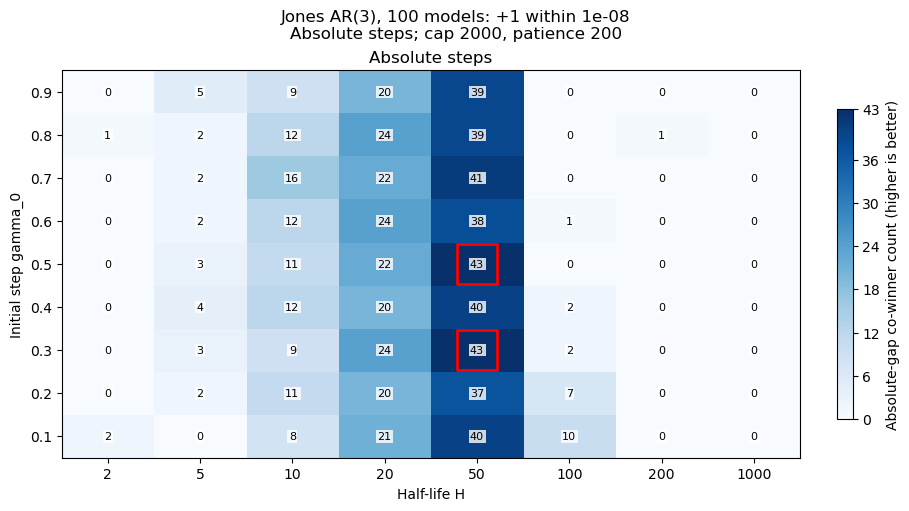

In [16]:
jones_win_figure_stem = f"02_jones_win_counts_eps_{epsilon_win_tolerance:g}"
fig, jones_win_matrices = plot_tuning_matrices(
    jones_win_ranking, scale_grid, half_life_grid, metric="wins", maximize=True, precision=0,
    title=(f"Jones AR(3), {number_of_coefficient_realizations} models: +1 within {epsilon_win_tolerance:g}\n"
           f"Absolute steps; cap {max_iterations}, patience {patience}"),
    colorbar_label="Absolute-gap co-winner count (higher is better)",
    filename=jones_win_figure_stem, pdf_directory=JONES_PDF_DIR, image_directory=JONES_IMAGE_DIR,
)
plt.show()
plt.close(fig)

In [17]:
with capture_output():
    print("Experiment 3 winners under the absolute-gap win-count rule:")
    for choice in jones_win_leaders.to_dict("records"):
        print(f"{choice['step_rule']}: scale={choice['step_value']:g}, H={choice['half_life']:g}, "
              f"beta={choice['beta']:.12g}; {int(choice['wins'])}/{number_of_coefficient_realizations} model wins.")
        print(f"Actual gamma0 range across models: [{choice['gamma0_min']:.12g}, {choice['gamma0_max']:.12g}].")
    print(f"One fixed u_0 throughout: {initial_direction}")
    print(f"PDF matrices: {JONES_PDF_DIR}")

## Experiment 3 repeated: stationarity check enabled

Repeat the preceding experiment on **the same Jones-sampled models and the same independent realization for each model**, using the same coefficient/process seeds, initial direction, tuning grid and width co-winner tolerance. The only optimizer change is **`stationarity_check=True`**. [Shared runner](../ar_tools/tuning.py), `tune_jones_ar_realizations`.

After the first `patience` evaluated directions of each attempt (200 by default), recover the coefficients from that attempt's **best-width direction** and check whether every companion eigenvalue has magnitude strictly below one. An undefined estimate or a failed check triggers a fresh random starting direction, a reset step schedule and a **fresh full iteration budget** (2,000 by default). Discard the failed attempt's best width. Repeat the checkpoint on each restarted attempt. A passing attempt continues without further checks or a final stationarity filter. [Optimizer checkpoint and restart rule](../ar_tools/descent.py), `projected_subgradient_empirical_width`.

The first starting direction is common to all configurations; restart directions are generated reproducibly by the optimizer's seeded stream. Allow at most `jones_stationarity_max_restarts` fresh starts per configuration (default 100). If this limit is exhausted, record the configuration/model run as failed with an undefined achieved width and **no win credit**. Report failures explicitly; a model on which every configuration fails awards no points and remains in the denominator. Evaluation totals include all discarded attempts. This can use more total evaluations than the original experiment.

Select configurations using the same full +1 width co-winner rule and retain all final ties. Variables and PDF/PNG exports use a separate `jones_stationarity_` prefix. The original Experiment 3 results remain available.


In [18]:
with capture_output():
    # Reuse the preceding experiment's model count and random streams.
    jones_stationarity_coefficient_seed = jones_coefficient_seed
    jones_stationarity_process_seed = jones_process_seed
    jones_stationarity_check = True
    jones_stationarity_max_restarts = 100

    jones_stationarity_configuration = {
        "experiment": "jones_stationarity_ar3_tuning", "T": int(T), "p": int(p),
        "replications": int(number_of_coefficient_realizations),
        "coefficient_sampling": "Jones1987_uniform_causal_AR3",
        "coefficient_seed": int(jones_stationarity_coefficient_seed), "process_seed": int(jones_stationarity_process_seed),
        "innovation_distribution": "Uniform(-1,1)", "burnin": int(burnin),
        "initial_direction": initial_direction.tolist(), "starts": 1, "optimizer_seed": int(optimizer_seed),
        "max_iterations": int(max_iterations), "patience": int(patience),
        "improvement_tolerance": float(improvement_tolerance),
        "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
        "step_rules": ["absolute"],
        "stationarity_check": bool(jones_stationarity_check),
        "max_restarts": int(jones_stationarity_max_restarts),
        "iteration_budget": "fresh_full_budget_per_attempt",
        "epsilon": float(epsilon_win_tolerance), "selection": "most_absolute_gap_co_winner_credits",
        "source_sha256": hashlib.sha256(b"".join(
            (AR_CODE_DIR / "ar_tools" / name).read_bytes()
            for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py", "coefficient_errors.py"]
        )).hexdigest(),
    }
    jones_stationarity_run_id = hashlib.sha256(repr(sorted(jones_stationarity_configuration.items())).encode()).hexdigest()[:16]
    JONES_STATIONARITY_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"jones_stationarity_{jones_stationarity_run_id}"
    JONES_STATIONARITY_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"jones_stationarity_{jones_stationarity_run_id}"
    for directory in (JONES_STATIONARITY_PDF_DIR, JONES_STATIONARITY_IMAGE_DIR):
        directory.mkdir(parents=True, exist_ok=True)
    print(f"Experiment 3 with stationarity check: {number_of_coefficient_realizations} Jones AR(3) models, T={T}; cap {max_iterations}, patience {patience}.")
    print(f"Common first starting direction for every candidate and model: {initial_direction}")
    print(f"Stationarity check: {jones_stationarity_check}; checkpoint after {patience} evaluations per attempt; "
          f"up to {jones_stationarity_max_restarts} restarts per configuration.")


In [19]:
with capture_output():
    jones_stationarity_experiment = tune_jones_ar_realizations(
        T, initial_direction, scale_grid, half_life_grid,
        replications=number_of_coefficient_realizations,
        coefficient_seed=jones_stationarity_coefficient_seed, process_seed=jones_stationarity_process_seed,
        burnin=burnin, iterations=max_iterations, patience=patience,
        improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed, progress=True, summarize=False,
        stationarity_check=jones_stationarity_check, max_restarts=jones_stationarity_max_restarts,
    )
    jones_stationarity_results = pd.DataFrame(jones_stationarity_experiment["results"])
    jones_stationarity_cases = pd.DataFrame(jones_stationarity_experiment["cases"])
    np.testing.assert_allclose(jones_stationarity_experiment["initial_direction"], initial_direction, atol=1e-15, rtol=0)
    assert len(jones_stationarity_cases) == number_of_coefficient_realizations
    assert len(jones_stationarity_results) == number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
    assert jones_stationarity_results["stationarity_check"].all()
    assert jones_stationarity_results["stationarity_check_passed"].eq(
        ~jones_stationarity_results["restart_limit_reached"]
    ).all()
    assert np.isfinite(jones_stationarity_results["minimum_width"]).eq(
        jones_stationarity_results["stationarity_check_passed"]
    ).all()
    assert jones_stationarity_results["restart_count"].between(0, jones_stationarity_max_restarts).all()
    assert jones_stationarity_results["attempt_count"].eq(jones_stationarity_results["restart_count"] + 1).all()
    assert jones_stationarity_results["final_evaluations"].between(patience, max_iterations).all()
    assert jones_stationarity_results.loc[
        jones_stationarity_results["stationarity_check_passed"], "checkpoint_spectral_radius"
    ].between(0, 1, inclusive="left").all()
    np.testing.assert_array_equal(
        jones_stationarity_results["total_evaluations"],
        jones_stationarity_results["restart_count"] * patience + jones_stationarity_results["final_evaluations"],
    )
    assert jones_stationarity_results["selected_start"].eq(1).all()
    assert jones_stationarity_cases["coefficient_seed"].is_unique and jones_stationarity_cases["process_seed"].is_unique
    assert jones_stationarity_cases[["phi_1", "phi_2", "phi_3"]].drop_duplicates().shape[0] == number_of_coefficient_realizations
    assert jones_stationarity_cases["spectral_radius"].between(0, 1, inclusive="left").all()
    print(f"Completed {len(jones_stationarity_cases)} distinct models and {len(jones_stationarity_results)} paired candidate runs.")

    # Verify that the repeat uses exactly the original model/path inputs.
    jones_stationarity_pairing_columns = [
        "replication", "T", "coefficient_seed", "process_seed", "phi_1", "phi_2", "phi_3",
        "pacf_1", "pacf_2", "pacf_3", "spectral_radius",
        "population_minimum_width", "empirical_true_direction_width",
    ]
    pd.testing.assert_frame_equal(
        jones_cases[jones_stationarity_pairing_columns].reset_index(drop=True),
        jones_stationarity_cases[jones_stationarity_pairing_columns].reset_index(drop=True),
    )
    print(f"Restarted runs: {int(jones_stationarity_results['restart_count'].gt(0).sum())}/"
          f"{len(jones_stationarity_results)}; total restarts: {int(jones_stationarity_results['restart_count'].sum())}.")
    print(f"Total evaluated directions, including discarded attempts: "
          f"{int(jones_stationarity_results['total_evaluations'].sum()):,}.")

    print(f"Runs that exhausted the restart limit (no width win credit): "
          f"{int(jones_stationarity_results['restart_limit_reached'].sum())}/{len(jones_stationarity_results)}.")


In [20]:
with capture_output():
    jones_stationarity_model_columns = [
        "replication", "phi_1", "phi_2", "phi_3", "pacf_1", "pacf_2", "pacf_3",
        "spectral_radius", "coefficient_seed", "process_seed", "grid_best_width",
        "population_minimum_width", "grid_population_width_gap",
        "empirical_true_direction_width", "grid_empirical_true_direction_gap",
        "restart_count", "total_evaluations", "failed_runs",
    ]
    print("All sampled models and seeds:")
    with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.precision", 8):
        display(jones_stationarity_cases[jones_stationarity_model_columns])
    print(f"Companion spectral-radius range: [{jones_stationarity_cases['spectral_radius'].min():.8f}, "
          f"{jones_stationarity_cases['spectral_radius'].max():.8f}].")

In [21]:
with capture_output():
    jones_stationarity_win_experiment = summarize_configuration_wins(
        jones_stationarity_results.to_dict("records"), score_key="minimum_width", epsilon=epsilon_win_tolerance, allow_nonfinite=True,
    )
    jones_stationarity_win_step_ranges = jones_stationarity_results.groupby("candidate_id", as_index=False).agg(
        gamma0_min=("gamma0", "min"), gamma0_max=("gamma0", "max"),
        total_restarts=("restart_count", "sum"),
    )
    jones_stationarity_win_ranking = pd.DataFrame(jones_stationarity_win_experiment["ranking"]).rename(
        columns={"rank": "win_rank", "undefined_scores": "failed_runs"},
    ).merge(jones_stationarity_win_step_ranges, on="candidate_id", validate="one_to_one").sort_values("win_rank")
    jones_stationarity_win_leaders = jones_stationarity_win_ranking.loc[
        jones_stationarity_win_ranking["wins"] == jones_stationarity_win_ranking["wins"].max()
    ].copy()
    jones_stationarity_win_winners = pd.DataFrame(jones_stationarity_win_experiment["winners"])
    assert jones_stationarity_win_experiment["cases"] == number_of_coefficient_realizations
    assert jones_stationarity_win_ranking["wins"].between(0, number_of_coefficient_realizations).all()
    assert jones_stationarity_win_ranking["wins"].sum() == len(jones_stationarity_win_winners) == jones_stationarity_win_experiment["total_points"]
    assert not jones_stationarity_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
    assert (jones_stationarity_win_winners["winning_score"] <= jones_stationarity_win_winners["winning_threshold"]).all()
    jones_stationarity_win_columns = [
        "win_rank", "step_rule", "step_value", "half_life", "beta",
        "wins", "win_rate", "mean_evaluations", "total_restarts", "failed_runs",
    ]
    print(f"Experiment 3 with stationarity check selection: +1 to every configuration within {epsilon_win_tolerance:g} of each model's best achieved width.")
    with pd.option_context("display.max_columns", None, "display.precision", 10):
        display(jones_stationarity_win_ranking[jones_stationarity_win_columns].head(15))
        print("All configurations with the highest win count:")
        display(jones_stationarity_win_leaders[jones_stationarity_win_columns])
    print(f"{jones_stationarity_win_experiment['cases']} models; {jones_stationarity_win_experiment['total_points']} full +1 credits; "
          f"{jones_stationarity_win_experiment['tied_cases']} models with multiple co-winners.")
    assert jones_stationarity_win_winners["stationarity_check_passed"].all()
    print(f"Models with no successful configuration: {jones_stationarity_win_experiment['undefined_cases']} "
          f"(retained in the denominator).")


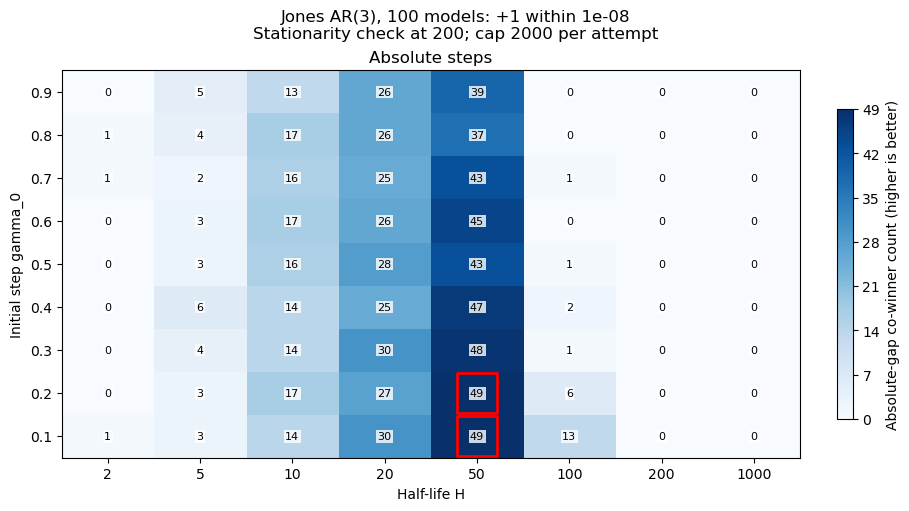

In [22]:
jones_stationarity_win_figure_stem = f"03_jones_stationarity_win_counts_eps_{epsilon_win_tolerance:g}"
fig, jones_stationarity_win_matrices = plot_tuning_matrices(
    jones_stationarity_win_ranking, scale_grid, half_life_grid, metric="wins", maximize=True, precision=0,
    title=(f"Jones AR(3), {number_of_coefficient_realizations} models: +1 within {epsilon_win_tolerance:g}\n"
           f"Stationarity check at {patience}; cap {max_iterations} per attempt"),
    colorbar_label="Absolute-gap co-winner count (higher is better)",
    filename=jones_stationarity_win_figure_stem, pdf_directory=JONES_STATIONARITY_PDF_DIR, image_directory=JONES_STATIONARITY_IMAGE_DIR,
)
plt.show()
plt.close(fig)

In [23]:
with capture_output():
    print("Experiment 3 with stationarity check: winners under the absolute-gap win-count rule:")
    for choice in jones_stationarity_win_leaders.to_dict("records"):
        print(f"{choice['step_rule']}: scale={choice['step_value']:g}, H={choice['half_life']:g}, "
              f"beta={choice['beta']:.12g}; {int(choice['wins'])}/{number_of_coefficient_realizations} model wins.")
        print(f"Restarts across all models: {int(choice['total_restarts'])}; "
              f"failed runs: {int(choice['failed_runs'])}.")
        print(f"Actual gamma0 range across models: [{choice['gamma0_min']:.12g}, {choice['gamma0_max']:.12g}].")
    print(f"Common first starting direction: {initial_direction}")
    print(f"PDF matrices: {JONES_STATIONARITY_PDF_DIR}")

## Experiment 3 repeated: data-dependent initial step $\gamma_0=c/L$

Repeat the **same 100 Jones models and their same single realizations**, common first direction and optimizer random streams. Change only the initial-step rule to $\gamma_0=c/L$, where
$$L=\max_{i,j}\|X_i-X_j\|_2$$
is the exact Euclidean diameter of the empirical four-coordinate window cloud. Compute $L$ once per model. Search $c\in\{0.1,0.2,\ldots,0.9\}$ and the existing half-life grid. This is an explicit opt-in in the [shared tuner](../ar_tools/tuning.py), `tune_geometric_half_life_schedules`; the unified optimizer still receives the resulting numerical initial step.

Keep **stationarity checking enabled**, patience 200, a fresh 2,000-evaluation budget per attempt, and up to 100 restarts. Width credits use epsilon $10^{-8}$; coefficient credits use per-coefficient MAE epsilon $10^{-2}$. Failed fits receive no credit and remain in the denominator. The matrix uses red boxes for width leaders and green boxes for coefficient-error leaders. The final comparison uses the preceding absolute-step stationarity repeat on exactly these models, reports failures and attempts, and computes raw coefficient L1 errors only where estimates are finite. [Restart implementation](../ar_tools/descent.py), `projected_subgradient_empirical_width`; [coefficient metric](../ar_tools/coefficient_errors.py), `coefficient_mae`.


In [70]:
with capture_output():
    # Refresh helpers when continuing in an already-open kernel.
    tuning_tools = importlib.reload(tuning_tools)
    tune_jones_ar_realizations = tuning_tools.tune_jones_ar_realizations
    with plt.rc_context():
        tuning_plot_tools = importlib.reload(tuning_plot_tools)
        plot_tuning_matrices = tuning_plot_tools.plot_tuning_matrices
    # Reuse the original Experiment 3 models and paths.
    jones_scaled_coefficient_seed = jones_coefficient_seed
    jones_scaled_process_seed = jones_process_seed
    jones_scaled_check = True
    jones_scaled_n_jobs = 4
    jones_scaled_step_rule = "diameter_normalized"
    jones_scaled_max_restarts = 100

    jones_scaled_configuration = {
        "experiment": "jones_scaled_ar3_tuning", "T": int(T), "p": int(p),
        "replications": int(number_of_coefficient_realizations),
        "coefficient_sampling": "Jones1987_uniform_causal_AR3",
        "coefficient_seed": int(jones_scaled_coefficient_seed), "process_seed": int(jones_scaled_process_seed),
        "innovation_distribution": "Uniform(-1,1)", "burnin": int(burnin),
        "initial_direction": initial_direction.tolist(), "starts": 1, "optimizer_seed": int(optimizer_seed),
        "max_iterations": int(max_iterations), "patience": int(patience),
        "improvement_tolerance": float(improvement_tolerance),
        "scale_grid": scale_grid.tolist(), "half_life_grid": half_life_grid.tolist(),
        "step_rules": [jones_scaled_step_rule],
        "diameter": "max_pairwise_euclidean_distance", "parallel_workers": int(jones_scaled_n_jobs),
        "epsilon_coefficient_mae": float(coefficient_epsilon_win_tolerance),
        "stationarity_check": bool(jones_scaled_check),
        "max_restarts": int(jones_scaled_max_restarts),
        "iteration_budget": "fresh_full_budget_per_attempt",
        "epsilon": float(epsilon_win_tolerance), "selection": "most_absolute_gap_co_winner_credits",
        "source_sha256": hashlib.sha256(b"".join(
            (AR_CODE_DIR / "ar_tools" / name).read_bytes()
            for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py", "coefficient_errors.py"]
        )).hexdigest(),
    }
    jones_scaled_run_id = hashlib.sha256(repr(sorted(jones_scaled_configuration.items())).encode()).hexdigest()[:16]
    JONES_SCALED_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"jones_scaled_{jones_scaled_run_id}"
    JONES_SCALED_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"jones_scaled_{jones_scaled_run_id}"
    for directory in (JONES_SCALED_PDF_DIR, JONES_SCALED_IMAGE_DIR):
        directory.mkdir(parents=True, exist_ok=True)
    print(f"Experiment 3 with gamma0=c/L and stationarity check: {number_of_coefficient_realizations} Jones AR(3) models, T={T}; cap {max_iterations}, patience {patience}.")
    print(f"Common first starting direction for every candidate and model: {initial_direction}")
    print(f"Stationarity check: {jones_scaled_check}; checkpoint after {patience} evaluations per attempt; "
          f"up to {jones_scaled_max_restarts} restarts per configuration.")

    print(f"Scale grid c: {scale_grid}; L is the empirical cloud diameter.")


In [71]:
with capture_output():
    jones_scaled_experiment = tune_jones_ar_realizations(
        T, initial_direction, scale_grid, half_life_grid,
        replications=number_of_coefficient_realizations,
        coefficient_seed=jones_scaled_coefficient_seed, process_seed=jones_scaled_process_seed,
        burnin=burnin, iterations=max_iterations, patience=patience,
        improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed, progress=True, summarize=False,
        stationarity_check=jones_scaled_check, max_restarts=jones_scaled_max_restarts,
        step_rule=jones_scaled_step_rule, n_jobs=jones_scaled_n_jobs,
    )
    jones_scaled_results = pd.DataFrame(jones_scaled_experiment["results"])
    jones_scaled_cases = pd.DataFrame(jones_scaled_experiment["cases"])
    np.testing.assert_allclose(jones_scaled_experiment["initial_direction"], initial_direction, atol=1e-15, rtol=0)
    assert len(jones_scaled_cases) == number_of_coefficient_realizations
    assert len(jones_scaled_results) == number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
    assert jones_scaled_results["stationarity_check"].all()
    assert jones_scaled_results["stationarity_check_passed"].eq(
        ~jones_scaled_results["restart_limit_reached"]
    ).all()
    assert np.isfinite(jones_scaled_results["minimum_width"]).eq(
        jones_scaled_results["stationarity_check_passed"]
    ).all()
    assert jones_scaled_results["restart_count"].between(0, jones_scaled_max_restarts).all()
    assert jones_scaled_results["attempt_count"].eq(jones_scaled_results["restart_count"] + 1).all()
    assert jones_scaled_results["final_evaluations"].between(patience, max_iterations).all()
    assert jones_scaled_results.loc[
        jones_scaled_results["stationarity_check_passed"], "checkpoint_spectral_radius"
    ].between(0, 1, inclusive="left").all()
    np.testing.assert_array_equal(
        jones_scaled_results["total_evaluations"],
        jones_scaled_results["restart_count"] * patience + jones_scaled_results["final_evaluations"],
    )
    assert jones_scaled_results["selected_start"].eq(1).all()
    assert jones_scaled_cases["coefficient_seed"].is_unique and jones_scaled_cases["process_seed"].is_unique
    assert jones_scaled_cases[["phi_1", "phi_2", "phi_3"]].drop_duplicates().shape[0] == number_of_coefficient_realizations
    assert jones_scaled_cases["spectral_radius"].between(0, 1, inclusive="left").all()
    print(f"Completed {len(jones_scaled_cases)} distinct models and {len(jones_scaled_results)} paired candidate runs.")

    # Verify that the repeat uses exactly the original model/path inputs.
    jones_scaled_pairing_columns = [
        "replication", "T", "coefficient_seed", "process_seed", "phi_1", "phi_2", "phi_3",
        "pacf_1", "pacf_2", "pacf_3", "spectral_radius",
        "population_minimum_width", "empirical_true_direction_width",
    ]
    pd.testing.assert_frame_equal(
        jones_stationarity_cases[jones_scaled_pairing_columns].reset_index(drop=True),
        jones_scaled_cases[jones_scaled_pairing_columns].reset_index(drop=True),
    )
    print(f"Restarted runs: {int(jones_scaled_results['restart_count'].gt(0).sum())}/"
          f"{len(jones_scaled_results)}; total restarts: {int(jones_scaled_results['restart_count'].sum())}.")
    print(f"Total evaluated directions, including discarded attempts: "
          f"{int(jones_scaled_results['total_evaluations'].sum()):,}.")

    print(f"Runs that exhausted the restart limit (no width win credit): "
          f"{int(jones_scaled_results['restart_limit_reached'].sum())}/{len(jones_scaled_results)}.")

    assert jones_scaled_results["step_rule"].eq("diameter_normalized").all()
    assert jones_scaled_results.groupby("replication")["cloud_diameter"].nunique().eq(1).all()
    np.testing.assert_allclose(
        jones_scaled_results["gamma0"] * jones_scaled_results["cloud_diameter"],
        jones_scaled_results["step_value"], rtol=2e-15, atol=0,
    )
    print(f"L range: {jones_scaled_results['cloud_diameter'].min():.8g} to "
          f"{jones_scaled_results['cloud_diameter'].max():.8g}; "
          f"mean attempts={jones_scaled_results['attempt_count'].mean():.4f}.")


In [72]:
with capture_output():
    jones_scaled_width_win_experiment = summarize_configuration_wins(
        jones_scaled_results.to_dict("records"),
        score_key="minimum_width", epsilon=epsilon_win_tolerance, allow_nonfinite=True,
    )
    jones_scaled_width_win_step_ranges = jones_scaled_results.groupby("candidate_id", as_index=False).agg(
        gamma0_min=("gamma0", "min"), gamma0_max=("gamma0", "max"),
        mean_attempts=("attempt_count", "mean"), total_restarts=("restart_count", "sum"),
    )
    jones_scaled_width_win_ranking = pd.DataFrame(jones_scaled_width_win_experiment["ranking"]).rename(
        columns={"rank": "win_rank", "undefined_scores": "failed_runs"},
    ).merge(jones_scaled_width_win_step_ranges, on="candidate_id", validate="one_to_one").sort_values("win_rank")
    jones_scaled_width_win_leaders = jones_scaled_width_win_ranking.loc[
        jones_scaled_width_win_ranking["wins"] == jones_scaled_width_win_ranking["wins"].max()
    ].copy()
    jones_scaled_width_win_winners = pd.DataFrame(jones_scaled_width_win_experiment["winners"])
    jones_scaled_width_win_cases = pd.DataFrame(jones_scaled_width_win_experiment["case_summaries"])
    assert jones_scaled_width_win_experiment["epsilon"] == epsilon_win_tolerance
    assert jones_scaled_width_win_experiment["cases"] == number_of_coefficient_realizations
    assert jones_scaled_width_win_ranking["wins"].between(0, number_of_coefficient_realizations).all()
    assert jones_scaled_width_win_ranking["wins"].sum() == len(jones_scaled_width_win_winners) == jones_scaled_width_win_experiment["total_points"]
    assert jones_scaled_width_win_cases["co_winners"].sum() == len(jones_scaled_width_win_winners)
    if not jones_scaled_width_win_winners.empty:
        assert not jones_scaled_width_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
        assert (jones_scaled_width_win_winners["winning_score"] <= jones_scaled_width_win_winners["winning_threshold"]).all()
        assert jones_scaled_width_win_winners["stationarity_check_passed"].all()

    jones_scaled_width_win_columns = [
        "win_rank", "step_rule", "step_value", "half_life", "beta",
        "wins", "win_rate", "failed_runs", "mean_attempts", "mean_evaluations",
    ]

    print(f"Experiment 3, gamma0=c/L: {number_of_coefficient_realizations} paths; cap {max_iterations} per attempt, patience {patience}.")
    print(f"+1 to EVERY configuration with achieved width <= path minimum + {epsilon_win_tolerance:g}.")
    with pd.option_context("display.max_columns", None, "display.precision", 10):
        display(jones_scaled_width_win_ranking[jones_scaled_width_win_columns].head(15))
        print("All configurations with the highest absolute-gap win count:")
        display(jones_scaled_width_win_leaders[jones_scaled_width_win_columns])
    print(f"{jones_scaled_width_win_experiment['cases']} realizations; {jones_scaled_width_win_experiment['total_points']} full +1 credits; "
          f"{jones_scaled_width_win_experiment['tied_cases']} paths with multiple co-winners; "
          f"maximum {jones_scaled_width_win_experiment['maximum_co_winners']} co-winners on one path.")
    for choice in jones_scaled_width_win_leaders.to_dict("records"):
        print(f"Absolute-gap win-count leader: {choice['step_rule']}, scale={choice['step_value']:g}, "
              f"H={choice['half_life']:g}, beta={choice['beta']:.12g}; "
              f"wins={int(choice['wins'])}/{number_of_coefficient_realizations}.")
    print(f"Paths with no successful configuration: {jones_scaled_width_win_experiment['undefined_cases']} "
          f"(retained in the denominator).")


In [73]:
with capture_output():
    # Recover coefficients from each configuration's recorded minimum-width direction.
    jones_scaled_coefficient_diagnostics = jones_scaled_results.copy()
    jones_scaled_directions = jones_scaled_results[[f"u_{j}" for j in range(p + 1)]].to_numpy(dtype=float)
    jones_scaled_coefficients = np.full((len(jones_scaled_results), p), np.nan)
    jones_scaled_coefficient_valid = (
        np.isfinite(jones_scaled_directions).all(axis=1) & (np.abs(jones_scaled_directions[:, 0]) > 1e-10)
    )
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        np.divide(-jones_scaled_directions[:, 1:], jones_scaled_directions[:, :1],
                  out=jones_scaled_coefficients, where=jones_scaled_coefficient_valid[:, None])
        jones_scaled_coefficient_errors = coefficient_mae(
            jones_scaled_coefficients, jones_scaled_results[[f"phi_{j+1}" for j in range(p)]].to_numpy(),
        )
    jones_scaled_coefficient_valid &= (
        np.isfinite(jones_scaled_coefficients).all(axis=1) & np.isfinite(jones_scaled_coefficient_errors)
    )
    jones_scaled_coefficient_errors[~jones_scaled_coefficient_valid] = np.nan
    for j in range(p):
        jones_scaled_coefficient_diagnostics[f"estimated_phi_{j+1}"] = jones_scaled_coefficients[:, j]
    jones_scaled_coefficient_diagnostics["coefficient_valid"] = jones_scaled_coefficient_valid
    jones_scaled_coefficient_diagnostics["coefficient_mae"] = jones_scaled_coefficient_errors

    jones_scaled_coefficient_win_experiment = summarize_configuration_wins(
        jones_scaled_coefficient_diagnostics.to_dict("records"), score_key="coefficient_mae",
        epsilon=coefficient_epsilon_win_tolerance, allow_nonfinite=True,
    )
    jones_scaled_coefficient_win_ranking = pd.DataFrame(jones_scaled_coefficient_win_experiment["ranking"]).rename(
        columns={"rank": "jones_scaled_coefficient_win_rank", "wins": "coefficient_wins",
                 "win_rate": "jones_scaled_coefficient_win_rate", "undefined_scores": "undefined_coefficients"},
    )
    jones_scaled_coefficient_win_leaders = jones_scaled_coefficient_win_ranking.loc[
        jones_scaled_coefficient_win_ranking["coefficient_wins"] == jones_scaled_coefficient_win_ranking["coefficient_wins"].max()
    ].copy()
    jones_scaled_coefficient_win_winners = pd.DataFrame(jones_scaled_coefficient_win_experiment["winners"])
    jones_scaled_coefficient_win_cases = pd.DataFrame(jones_scaled_coefficient_win_experiment["case_summaries"])
    jones_scaled_combined_win_ranking = jones_scaled_width_win_ranking.merge(
        jones_scaled_coefficient_win_ranking[["candidate_id", "jones_scaled_coefficient_win_rank", "coefficient_wins",
                                 "jones_scaled_coefficient_win_rate", "undefined_coefficients"]],
        on="candidate_id", validate="one_to_one",
    )
    assert jones_scaled_coefficient_win_experiment["epsilon"] == coefficient_epsilon_win_tolerance
    assert jones_scaled_coefficient_win_experiment["cases"] == number_of_coefficient_realizations
    assert jones_scaled_coefficient_win_ranking["coefficient_wins"].between(0, number_of_coefficient_realizations).all()
    assert jones_scaled_coefficient_win_ranking["coefficient_wins"].sum() == len(jones_scaled_coefficient_win_winners)
    assert jones_scaled_coefficient_win_cases["co_winners"].sum() == jones_scaled_coefficient_win_experiment["total_points"]
    if not jones_scaled_coefficient_win_winners.empty:
        assert not jones_scaled_coefficient_win_winners.duplicated(["replication", "T", "candidate_id"]).any()
        assert (jones_scaled_coefficient_win_winners["winning_score"] <= jones_scaled_coefficient_win_winners["winning_threshold"]).all()

    jones_scaled_coefficient_win_columns = [
        "jones_scaled_coefficient_win_rank", "step_rule", "step_value", "half_life", "beta",
        "coefficient_wins", "jones_scaled_coefficient_win_rate", "undefined_coefficients",
    ]
    print(f"+1 to EVERY configuration with coefficient MAE <= path minimum + {coefficient_epsilon_win_tolerance:g}.")
    with pd.option_context("display.max_columns", None, "display.precision", 10):
        display(jones_scaled_coefficient_win_ranking[jones_scaled_coefficient_win_columns].head(15))
        print("All configurations with the highest coefficient-error win count:")
        display(jones_scaled_coefficient_win_leaders[jones_scaled_coefficient_win_columns])
    print(f"{jones_scaled_coefficient_win_experiment['cases']} realizations; {jones_scaled_coefficient_win_experiment['total_points']} full +1 coefficient credits; "
          f"{jones_scaled_coefficient_win_experiment['tied_cases']} paths with multiple coefficient co-winners.")
    print(f"Undefined coefficient estimates: {(~jones_scaled_coefficient_valid).sum()}; "
          f"paths with no finite coefficient estimate: {jones_scaled_coefficient_win_experiment['undefined_cases']}.")

    jones_scaled_coefficient_diagnostics["coefficient_l1"] = p * jones_scaled_coefficient_diagnostics["coefficient_mae"]
    jones_scaled_error_summary = jones_scaled_coefficient_diagnostics.groupby("candidate_id", as_index=False).agg(
        completed_coefficient_fits=("coefficient_l1", "count"),
        mean_coefficient_l1_completed=("coefficient_l1", "mean"),
        median_coefficient_l1_completed=("coefficient_l1", "median"),
    )
    jones_scaled_combined_win_ranking = jones_scaled_combined_win_ranking.merge(
        jones_scaled_error_summary, on="candidate_id", validate="one_to_one",
    )


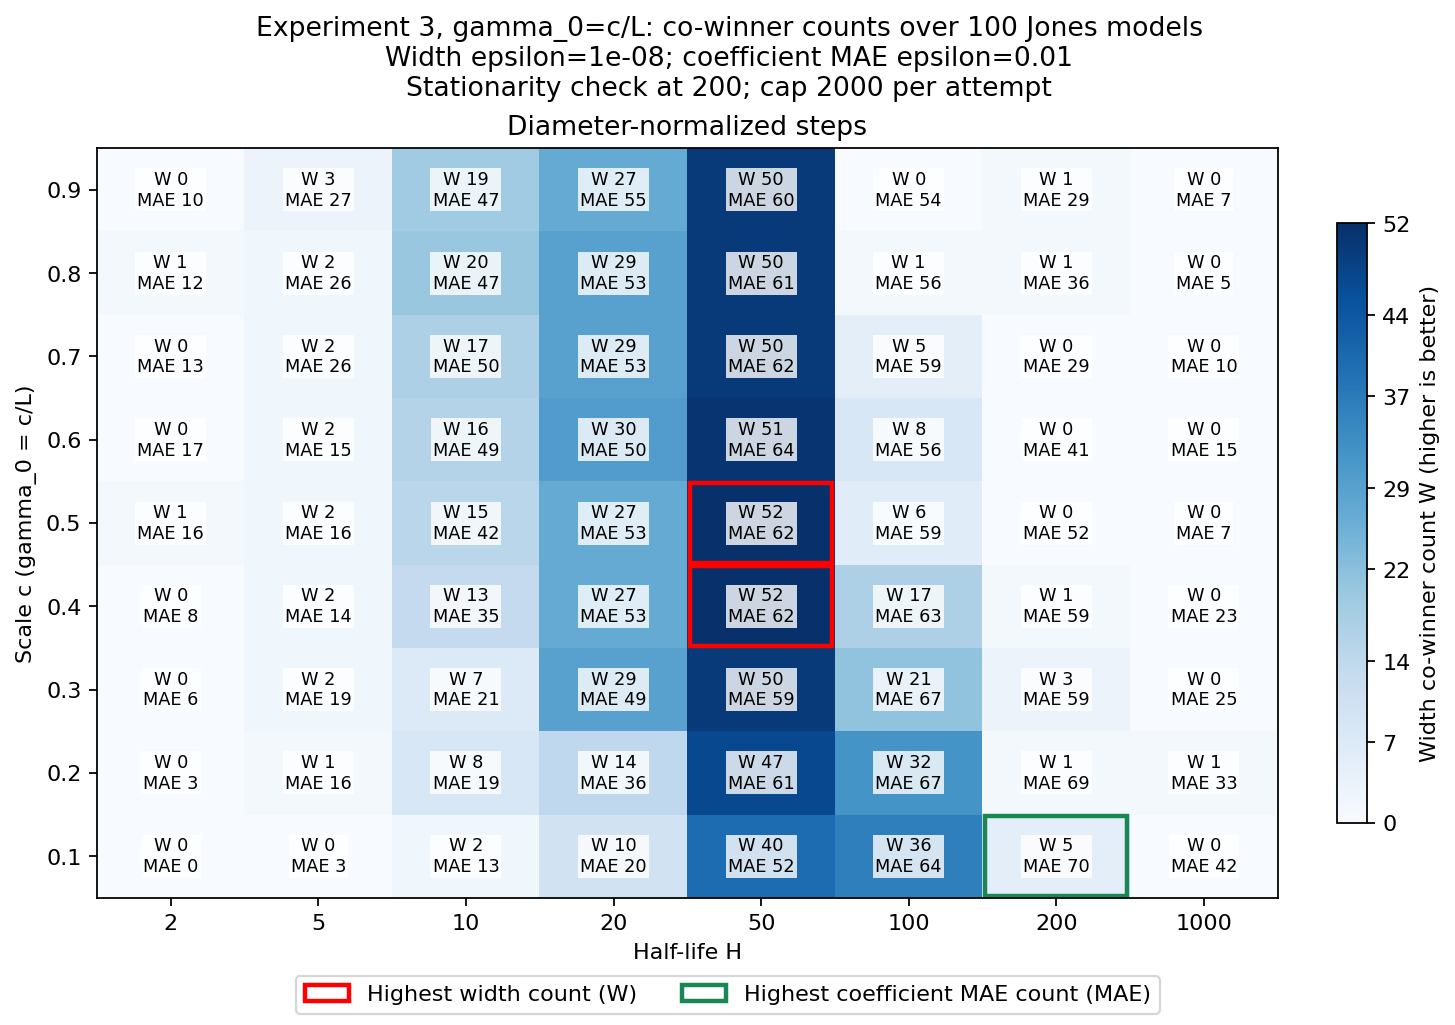

In [74]:
jones_scaled_win_figure_stem = (
    f"09_jones_scaled_width_{epsilon_win_tolerance:g}_coefficient_mae_{coefficient_epsilon_win_tolerance:g}"
)
fig, jones_scaled_win_matrices = plot_tuning_matrices(
    jones_scaled_combined_win_ranking, scale_grid, half_life_grid,
    metric="wins", secondary_metric="coefficient_wins", maximize=True, precision=0,
    title=(f"Experiment 3, gamma_0=c/L: co-winner counts over {number_of_coefficient_realizations} Jones models\n"
           f"Width epsilon={epsilon_win_tolerance:g}; coefficient MAE epsilon={coefficient_epsilon_win_tolerance:g}\n"
           f"Stationarity check at {patience}; cap {max_iterations} per attempt"),
    colorbar_label="Width co-winner count W (higher is better)",
    filename=jones_scaled_win_figure_stem, pdf_directory=JONES_SCALED_PDF_DIR, image_directory=JONES_SCALED_IMAGE_DIR,
)
plt.show()
plt.close(fig)


In [75]:
with capture_output():
    jones_scaled_selection_columns = [
        "step_value", "half_life", "beta", "wins", "coefficient_wins", "gamma0_min", "gamma0_max",
        "failed_runs", "mean_attempts", "completed_coefficient_fits",
        "mean_coefficient_l1_completed", "median_coefficient_l1_completed",
    ]
    jones_scaled_selection = jones_scaled_combined_win_ranking.loc[
        jones_scaled_combined_win_ranking["wins"].eq(jones_scaled_combined_win_ranking["wins"].max())
        & jones_scaled_combined_win_ranking["wins"].gt(0)
    ].copy()
    print("Experiment 3, gamma0=c/L: all width-count leaders (step_value is c):")
    with pd.option_context("display.max_columns", None, "display.precision", 8):
        display(jones_scaled_selection[jones_scaled_selection_columns])
    print("Coefficient L1 means/medians use finite estimates only; attempt means include failed fits.")
    print(f"All runs: {int(jones_scaled_results['restart_limit_reached'].sum())}/{len(jones_scaled_results)} failed; "
          f"mean attempts={jones_scaled_results['attempt_count'].mean():.4f}.")
    print(f"PDF matrix: {JONES_SCALED_PDF_DIR / (jones_scaled_win_figure_stem + '.pdf')}")


In [76]:
with capture_output():
    # Compare the two step rules on the same model/path inputs without rerunning either grid.
    jones_scaled_comparison_rows = []
    jones_scaled_comparison_fits = {}
    jones_scaled_comparison_leaders = {}
    for rule, results in [("absolute", jones_stationarity_results),
                          ("diameter_normalized", jones_scaled_results)]:
        diagnostics = results.copy()
        directions = diagnostics[[f"u_{j}" for j in range(p + 1)]].to_numpy()
        estimates = np.full((len(diagnostics), p), np.nan)
        valid = np.isfinite(directions).all(axis=1) & (np.abs(directions[:, 0]) > 1e-10)
        with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
            np.divide(-directions[:, 1:], directions[:, :1], out=estimates, where=valid[:, None])
            diagnostics["coefficient_l1"] = p * coefficient_mae(
                estimates, diagnostics[[f"phi_{j+1}" for j in range(p)]].to_numpy(),
            )
        jones_scaled_comparison_fits[rule] = diagnostics
        width_counts = pd.DataFrame(summarize_configuration_wins(
            results.to_dict("records"), epsilon=epsilon_win_tolerance, allow_nonfinite=True,
        )["ranking"])
        leaders = width_counts.loc[width_counts["wins"].eq(width_counts["wins"].max())]
        jones_scaled_comparison_leaders[rule] = leaders
        for scope, subset in [("all 72 configurations", diagnostics)] + [
            (f"width leader: scale={choice['step_value']:g}, H={choice['half_life']:g}",
             diagnostics.loc[diagnostics["candidate_id"].eq(choice["candidate_id"])])
            for choice in leaders.to_dict("records")
        ]:
            jones_scaled_comparison_rows.append({
                "step_rule": rule, "scope": scope, "runs": len(subset),
                "failed_runs": int(subset["restart_limit_reached"].sum()),
                "mean_attempts": subset["attempt_count"].mean(),
                "finite_coefficient_estimates": int(subset["coefficient_l1"].notna().sum()),
                "mean_coefficient_l1_completed": subset["coefficient_l1"].mean(),
                "median_coefficient_l1_completed": subset["coefficient_l1"].median(),
            })
    jones_scaled_comparison = pd.DataFrame(jones_scaled_comparison_rows)
    print("Failures and attempts include all runs; L1 summaries condition on finite returned estimates:")
    with pd.option_context("display.max_columns", None, "display.precision", 8):
        display(jones_scaled_comparison)

    # Error changes on a common finite subset, for every pair of width-count leaders.
    jones_scaled_paired_rows = []
    for before in jones_scaled_comparison_leaders["absolute"].to_dict("records"):
        for after in jones_scaled_comparison_leaders["diameter_normalized"].to_dict("records"):
            paired = jones_scaled_comparison_fits["absolute"].loc[
                lambda frame: frame["candidate_id"].eq(before["candidate_id"])
            ].merge(jones_scaled_comparison_fits["diameter_normalized"].loc[
                lambda frame: frame["candidate_id"].eq(after["candidate_id"])
            ], on=["replication", "T"], suffixes=("_absolute", "_scaled"), validate="one_to_one")
            finite = paired["coefficient_l1_absolute"].notna() & paired["coefficient_l1_scaled"].notna()
            width_finite = paired["minimum_width_absolute"].notna() & paired["minimum_width_scaled"].notna()
            jones_scaled_paired_rows.append({
                "absolute_gamma0": before["step_value"], "absolute_H": before["half_life"],
                "scaled_c": after["step_value"], "scaled_H": after["half_life"],
                "common_finite_estimates": int(finite.sum()),
                "mean_L1_absolute": paired.loc[finite, "coefficient_l1_absolute"].mean(),
                "mean_L1_scaled": paired.loc[finite, "coefficient_l1_scaled"].mean(),
                "median_L1_absolute": paired.loc[finite, "coefficient_l1_absolute"].median(),
                "median_L1_scaled": paired.loc[finite, "coefficient_l1_scaled"].median(),
                "common_finite_widths": int(width_finite.sum()),
                "scaled_narrower_beyond_epsilon": int((width_finite & (
                    paired["minimum_width_scaled"] < paired["minimum_width_absolute"] - epsilon_win_tolerance)).sum()),
                "absolute_narrower_beyond_epsilon": int((width_finite & (
                    paired["minimum_width_absolute"] < paired["minimum_width_scaled"] - epsilon_win_tolerance)).sum()),
            })
    jones_scaled_paired_comparison = pd.DataFrame(jones_scaled_paired_rows)
    print("Paired comparison of width-count leaders on their common finite models:")
    with pd.option_context("display.max_columns", None, "display.precision", 8):
        display(jones_scaled_paired_comparison)

    # A common 144-configuration contest makes width counts comparable across rules.
    jones_scaled_union = pd.concat([jones_stationarity_results, jones_scaled_results], ignore_index=True)
    jones_scaled_union_counts = pd.DataFrame(summarize_configuration_wins(
        jones_scaled_union.to_dict("records"), epsilon=epsilon_win_tolerance, allow_nonfinite=True,
    )["ranking"])
    print("Width-count ranking in the combined absolute + c/L grid (144 configurations):")
    with pd.option_context("display.max_columns", None, "display.precision", 8):
        display(jones_scaled_union_counts[["step_rule", "step_value", "half_life", "wins", "undefined_scores"]].head(15))


## Experiment 4: the same 100 Jones models, deterministic $u_0=e_1$

Reuse **the exact coefficient vectors and innovation paths from the original Experiment 3**. Change only the starting direction to $e_1=(1,0,0,0)$, and evaluate both initial-step rules: **absolute** $\gamma_0=s$ and **diameter-normalized** $\gamma_0=s/L$, with $L$ the exact Euclidean diameter of each empirical cloud. Both use $s\in\{0.1,0.2,\ldots,0.9\}$ and $H\in\{2,5,10,20,50,100,200,1000\}$, $\beta=2^{-1/H}$. This gives **72 configurations per rule, 144 per model and 14,400 runs for 100 models**. [Shared runner and diameter calculation](../ar_tools/tuning.py).

Match the **original Experiment 3**, with $T=500$, burn-in 2,000, at most 2,000 evaluated directions, patience 200, and zero improvement tolerance. **Stationarity-triggered restarts are disabled**: every configuration starts at $e_1$ once. Stationarity and coefficient errors are reported afterward and do not filter the width results. This differs explicitly from the later Experiment 3 restart extensions. [Optimizer and stopping rule](../ar_tools/descent.py).

Each rule has its own 72-configuration width and coefficient-MAE co-winner counts, with tolerances $10^{-8}$ and $10^{-2}$ respectively. The separate combined 144-configuration table uses one common reference per model to compare the two rules. A full +1 is awarded to every qualifying configuration, exactly as in the earlier counting sections. Known coefficients enter diagnostics only. All numerical results remain in this notebook; figures are also saved as PDF and PNG.

In [77]:
with capture_output():
    # Refresh shared helpers when appending Experiment 4 in an existing kernel.
    tuning_tools = importlib.reload(tuning_tools)
    tune_jones_ar_realizations = tuning_tools.tune_jones_ar_realizations
    with plt.rc_context():
        tuning_plot_tools = importlib.reload(tuning_plot_tools)
        plot_tuning_matrices = tuning_plot_tools.plot_tuning_matrices

    e1_initial_direction = np.zeros(embedding_dimension, dtype=float)
    e1_initial_direction[0] = 1.0
    e1_step_rules = ("absolute", "diameter_normalized")
    e1_n_jobs = 4
    e1_configuration = {
        **jones_configuration,
        "experiment": "experiment_4_jones_ar3_e1",
        "initial_direction": e1_initial_direction.tolist(),
        "step_rules": list(e1_step_rules),
        "stationarity_check": False, "max_restarts": 0,
        "diameter": "max_pairwise_euclidean_distance",
        "parallel_workers": e1_n_jobs,
        "epsilon_coefficient_mae": float(coefficient_epsilon_win_tolerance),
        "source_sha256": hashlib.sha256(b"".join(
            (AR_CODE_DIR / "ar_tools" / name).read_bytes()
            for name in ["functions.py", "innovations.py", "descent.py", "tuning.py", "tuning_plots.py", "coefficient_errors.py"]
        )).hexdigest(),
    }
    e1_run_id = hashlib.sha256(repr(sorted(e1_configuration.items())).encode()).hexdigest()[:16]
    E1_PDF_DIR = OUTPUT_ROOT / "pdfs" / EXPERIMENT_NAME / f"experiment4_e1_{e1_run_id}"
    E1_IMAGE_DIR = OUTPUT_ROOT / "images" / EXPERIMENT_NAME / f"experiment4_e1_{e1_run_id}"
    for directory in (E1_PDF_DIR, E1_IMAGE_DIR):
        directory.mkdir(parents=True, exist_ok=True)
    print(f"Experiment 4: {number_of_coefficient_realizations} original Jones models and paths; u_0={e1_initial_direction}.")
    print(f"Rules: gamma0=s and gamma0=s/L; cap={max_iterations}, patience={patience}; one start, no restarts.")
    print(f"Coefficient seed={jones_coefficient_seed}; process seed={jones_process_seed}; run={e1_run_id}.")

In [78]:
with capture_output():
    e1_experiments = {}
    e1_pairing_columns = [
        "replication", "T", "coefficient_seed", "process_seed", "phi_1", "phi_2", "phi_3",
        "pacf_1", "pacf_2", "pacf_3", "spectral_radius",
        "population_minimum_width", "empirical_true_direction_width",
    ]
    for e1_rule in e1_step_rules:
        print(f"\nExperiment 4 — {e1_rule}", flush=True)
        e1_experiments[e1_rule] = tune_jones_ar_realizations(
            T, e1_initial_direction, scale_grid, half_life_grid,
            replications=number_of_coefficient_realizations,
            coefficient_seed=jones_coefficient_seed, process_seed=jones_process_seed,
            burnin=burnin, iterations=max_iterations, patience=patience,
            improvement_tolerance=improvement_tolerance, optimizer_seed=optimizer_seed,
            progress=True, summarize=False, stationarity_check=False, max_restarts=0,
            step_rule=e1_rule, n_jobs=e1_n_jobs,
        )
        e1_rule_cases = pd.DataFrame(e1_experiments[e1_rule]["cases"])
        pd.testing.assert_frame_equal(
            jones_cases[e1_pairing_columns].sort_values("replication").reset_index(drop=True),
            e1_rule_cases[e1_pairing_columns].sort_values("replication").reset_index(drop=True),
            check_exact=True,
        )
        np.testing.assert_array_equal(e1_experiments[e1_rule]["initial_direction"], e1_initial_direction)

    e1_results = pd.concat([
        pd.DataFrame(e1_experiments[rule]["results"]) for rule in e1_step_rules
    ], ignore_index=True)
    e1_expected_per_rule = number_of_coefficient_realizations * len(scale_grid) * len(half_life_grid)
    assert len(e1_results) == 2 * e1_expected_per_rule
    assert e1_results.groupby("step_rule").size().eq(e1_expected_per_rule).all()
    assert not e1_results.duplicated(["replication", "T", "candidate_id"]).any()
    assert e1_results["total_evaluations"].between(1, max_iterations).all()
    assert e1_results["selected_start"].eq(1).all()
    assert np.isfinite(e1_results["minimum_width"]).all()
    e1_scaled_rows = e1_results.loc[e1_results["step_rule"].eq("diameter_normalized")]
    assert e1_scaled_rows.groupby("replication")["cloud_diameter"].nunique().eq(1).all()
    np.testing.assert_allclose(
        e1_scaled_rows["gamma0"] * e1_scaled_rows["cloud_diameter"],
        e1_scaled_rows["step_value"], rtol=2e-15, atol=0,
    )
    np.testing.assert_array_equal(
        e1_results.loc[e1_results["step_rule"].eq("absolute"), "gamma0"],
        e1_results.loc[e1_results["step_rule"].eq("absolute"), "step_value"],
    )
    print(f"\nCompleted {len(e1_results):,} configurations on the same {number_of_coefficient_realizations} models and paths.")
    print("Exact model coefficients, partial autocorrelations, seeds and reference widths match original Experiment 3 for both rules.")
    print(f"Total evaluated directions: {int(e1_results['total_evaluations'].sum()):,}.")

### Returned coefficients and stationarity diagnostics

Recover coefficients from each returned best-width direction, using $\widehat\phi=-\widehat u_{1:}/\widehat u_0$. For consistency with the earlier notebook diagnostics, a first component of absolute value at most $10^{-10}$ is treated as undefined. MAE is the average absolute error over the three coefficients. Nonstationarity is checked on the returned coefficients, **after optimization**, with the existing companion-matrix test; this does not modify a run or its score. [Coefficient transformation and stationarity](../ar_tools/functions.py), [MAE implementation](../ar_tools/coefficient_errors.py).

In [79]:
with capture_output():
    e1_diagnostics = e1_results.copy()
    e1_directions = e1_diagnostics[[f"u_{j}" for j in range(embedding_dimension)]].to_numpy()
    e1_coefficient_valid = np.isfinite(e1_directions).all(axis=1) & (np.abs(e1_directions[:, 0]) > 1e-10)
    e1_estimated_coefficients = np.full((len(e1_diagnostics), p), np.nan)
    e1_estimated_coefficients[e1_coefficient_valid] = (
        -e1_directions[e1_coefficient_valid, 1:] / e1_directions[e1_coefficient_valid, :1]
    )
    e1_truth = e1_diagnostics[[f"phi_{j+1}" for j in range(p)]].to_numpy()
    e1_diagnostics["coefficient_mae"] = coefficient_mae(e1_estimated_coefficients, e1_truth)
    e1_diagnostics["coefficient_l1"] = p * e1_diagnostics["coefficient_mae"]
    e1_diagnostics["coefficient_defined"] = np.isfinite(e1_diagnostics["coefficient_mae"])
    e1_estimated_radii = np.full(len(e1_diagnostics), np.nan)
    for e1_row in np.flatnonzero(e1_diagnostics["coefficient_defined"].to_numpy()):
        e1_estimated_radii[e1_row] = np.max(np.abs(is_stationary(e1_estimated_coefficients[e1_row])[1]))
    e1_diagnostics["estimated_spectral_radius"] = e1_estimated_radii
    e1_diagnostics["nonstationary_estimate"] = e1_diagnostics["coefficient_defined"] & (e1_estimated_radii >= 1)
    for e1_j in range(p):
        e1_diagnostics[f"estimated_phi_{e1_j+1}"] = e1_estimated_coefficients[:, e1_j]
    e1_all_run_summary = e1_diagnostics.groupby("step_rule", as_index=False).agg(
        runs=("candidate_id", "size"), finite_coefficients=("coefficient_defined", "sum"),
        nonstationary_estimates=("nonstationary_estimate", "sum"),
        mean_coefficient_mae=("coefficient_mae", "mean"),
        median_coefficient_mae=("coefficient_mae", "median"),
        max_coefficient_mae=("coefficient_mae", "max"),
        total_evaluations=("total_evaluations", "sum"),
    )
    print("All configurations, including poorly performing settings; coefficient summaries use finite estimates:")
    with pd.option_context("display.max_columns", None, "display.precision", 8):
        display(e1_all_run_summary)

In [80]:
with capture_output():
    # Count each step rule's 72-configuration contest separately, as in earlier sections.
    e1_rule_rankings = {}
    e1_rule_leaders = {}
    e1_width_counts = {}
    e1_coefficient_counts = {}
    e1_count_columns = [
        "step_rule", "step_value", "half_life", "beta", "wins", "coefficient_wins",
        "gamma0_min", "gamma0_max", "nonstationary_estimates", "undefined_coefficients",
        "mean_coefficient_mae", "median_coefficient_mae", "mean_evaluations",
    ]
    for e1_rule in e1_step_rules:
        e1_rule_data = e1_diagnostics.loc[e1_diagnostics["step_rule"].eq(e1_rule)]
        e1_width_counts[e1_rule] = summarize_configuration_wins(
            e1_rule_data.to_dict("records"), score_key="minimum_width", epsilon=epsilon_win_tolerance,
        )
        e1_coefficient_counts[e1_rule] = summarize_configuration_wins(
            e1_rule_data.to_dict("records"), score_key="coefficient_mae",
            epsilon=coefficient_epsilon_win_tolerance, allow_nonfinite=True,
        )
        e1_coefficient_ranking = pd.DataFrame(e1_coefficient_counts[e1_rule]["ranking"])[
            ["candidate_id", "wins", "undefined_scores"]
        ].rename(columns={"wins": "coefficient_wins", "undefined_scores": "undefined_coefficients"})
        e1_rule_summary = e1_rule_data.groupby("candidate_id", as_index=False).agg(
            gamma0_min=("gamma0", "min"), gamma0_max=("gamma0", "max"),
            nonstationary_estimates=("nonstationary_estimate", "sum"),
            mean_coefficient_mae=("coefficient_mae", "mean"),
            median_coefficient_mae=("coefficient_mae", "median"),
            max_coefficient_mae=("coefficient_mae", "max"),
        )
        e1_rule_rankings[e1_rule] = pd.DataFrame(e1_width_counts[e1_rule]["ranking"]).merge(
            e1_coefficient_ranking, on="candidate_id", validate="one_to_one",
        ).merge(e1_rule_summary, on="candidate_id", validate="one_to_one")
        e1_rule_ranking = e1_rule_rankings[e1_rule]
        e1_rule_leaders[e1_rule] = e1_rule_ranking.loc[
            e1_rule_ranking["wins"].eq(e1_rule_ranking["wins"].max())
        ].copy()
        assert e1_width_counts[e1_rule]["cases"] == number_of_coefficient_realizations
        assert e1_rule_ranking["wins"].sum() == e1_width_counts[e1_rule]["total_points"]
        assert e1_rule_ranking["coefficient_wins"].sum() == e1_coefficient_counts[e1_rule]["total_points"]
        print(f"\nExperiment 4, {e1_rule}: top configurations in its own 72-configuration contest:")
        with pd.option_context("display.max_columns", None, "display.precision", 8):
            display(e1_rule_ranking[e1_count_columns].head(15))
            print("All width-count leaders:")
            display(e1_rule_leaders[e1_rule][e1_count_columns])

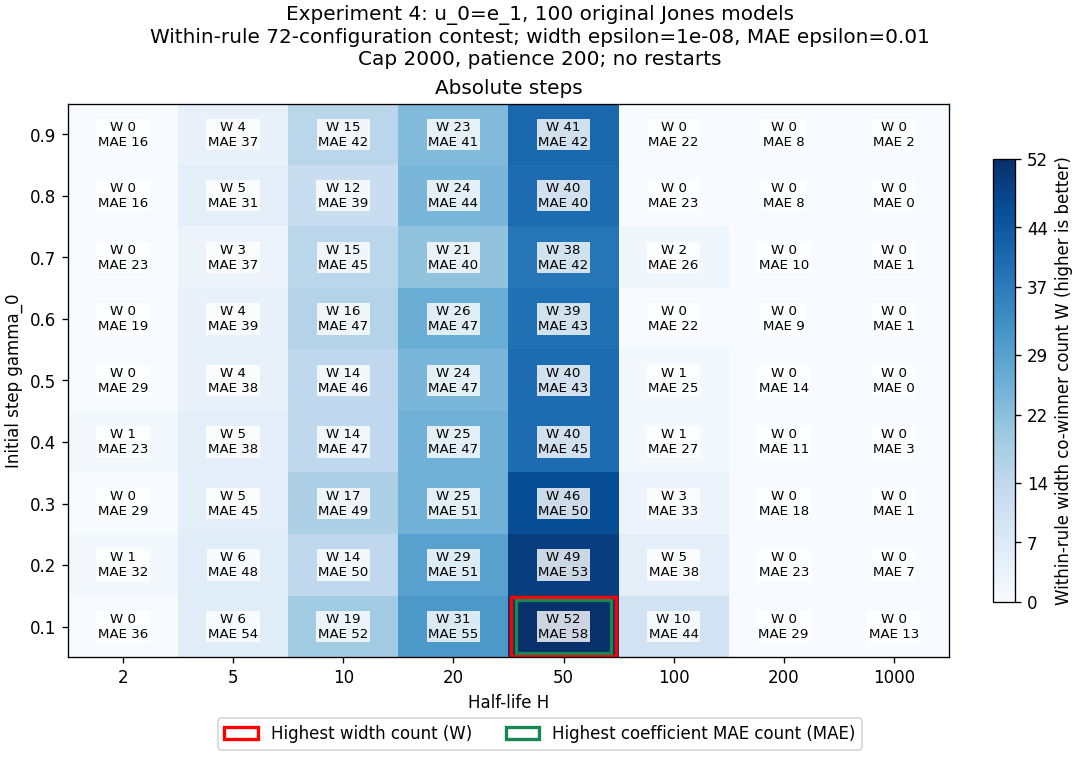

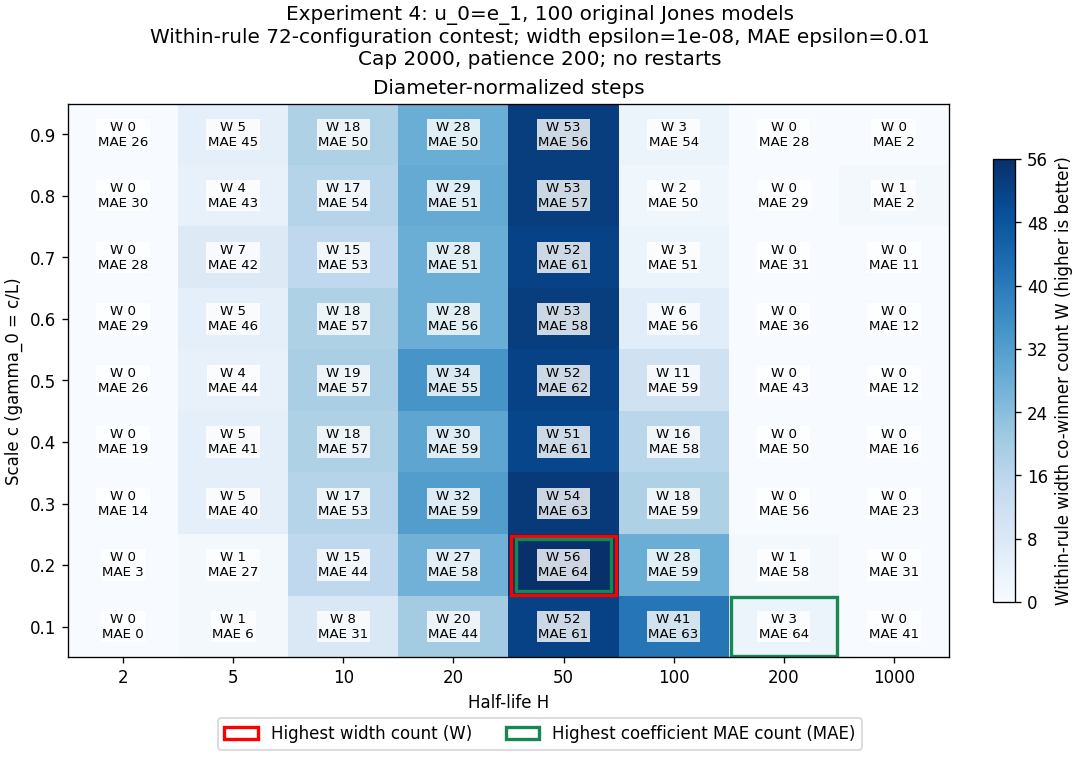

In [81]:
with capture_output(display=False):
    e1_win_matrices = {}
    for e1_rule in e1_step_rules:
        e1_figure_stem = f"10_experiment4_e1_{e1_rule}_width_{epsilon_win_tolerance:g}_coefficient_mae_{coefficient_epsilon_win_tolerance:g}"
        fig, e1_win_matrices[e1_rule] = plot_tuning_matrices(
            e1_rule_rankings[e1_rule], scale_grid, half_life_grid,
            metric="wins", secondary_metric="coefficient_wins", maximize=True, precision=0,
            title=(f"Experiment 4: u_0=e_1, {number_of_coefficient_realizations} original Jones models\n"
                   f"Within-rule 72-configuration contest; width epsilon={epsilon_win_tolerance:g}, MAE epsilon={coefficient_epsilon_win_tolerance:g}\n"
                   f"Cap {max_iterations}, patience {patience}; no restarts"),
            colorbar_label="Within-rule width co-winner count W (higher is better)",
            filename=e1_figure_stem, pdf_directory=E1_PDF_DIR, image_directory=E1_IMAGE_DIR,
        )
        plt.show()
        plt.close(fig)
    print(f"PDF matrices: {E1_PDF_DIR}")

### Compare both rules against the same 144-configuration reference

Within-rule counts use different reference minima. To compare the two rules directly, recompute width and coefficient-MAE co-winner counts over **all 144 configurations together** on each of the same 100 models. The following common-reference ranking is distinct from the preceding within-rule matrices. All tied leaders are retained; coefficient accuracy does not select the width winner. [Counting implementation](../ar_tools/tuning.py).

In [82]:
with capture_output():
    e1_common_width_counts = summarize_configuration_wins(
        e1_diagnostics.to_dict("records"), score_key="minimum_width", epsilon=epsilon_win_tolerance,
    )
    e1_common_coefficient_counts = summarize_configuration_wins(
        e1_diagnostics.to_dict("records"), score_key="coefficient_mae",
        epsilon=coefficient_epsilon_win_tolerance, allow_nonfinite=True,
    )
    e1_common_coefficients = pd.DataFrame(e1_common_coefficient_counts["ranking"])[
        ["candidate_id", "wins"]
    ].rename(columns={"wins": "coefficient_wins_common"})
    e1_common_ranking = pd.DataFrame(e1_common_width_counts["ranking"]).rename(
        columns={"wins": "width_wins_common"},
    ).merge(e1_common_coefficients, on="candidate_id", validate="one_to_one")
    e1_parameter_summaries = pd.concat(list(e1_rule_rankings.values()), ignore_index=True)[
        ["candidate_id", "gamma0_min", "gamma0_max", "nonstationary_estimates", "undefined_coefficients",
         "mean_coefficient_mae", "median_coefficient_mae", "max_coefficient_mae"]
    ]
    e1_common_ranking = e1_common_ranking.merge(e1_parameter_summaries, on="candidate_id", validate="one_to_one")
    e1_common_leaders = e1_common_ranking.loc[
        e1_common_ranking["width_wins_common"].eq(e1_common_ranking["width_wins_common"].max())
    ].copy()
    e1_common_columns = [
        "step_rule", "step_value", "half_life", "beta", "width_wins_common", "coefficient_wins_common",
        "gamma0_min", "gamma0_max", "nonstationary_estimates", "undefined_coefficients",
        "mean_coefficient_mae", "median_coefficient_mae",
    ]
    print("Common 144-configuration contest: top configurations, then all width-count leaders:")
    with pd.option_context("display.max_columns", None, "display.precision", 8):
        display(e1_common_ranking[e1_common_columns].head(20))
        display(e1_common_leaders[e1_common_columns])
    for e1_rule in e1_step_rules:
        e1_rule_common = e1_common_ranking.loc[e1_common_ranking["step_rule"].eq(e1_rule)]
        print(f"{e1_rule}: best common-reference width count = {int(e1_rule_common['width_wins_common'].max())}/{number_of_coefficient_realizations}.")

In [83]:
with capture_output():
    # Model-wise grid best is a diagnostic; it is not one deployable common schedule.
    e1_model_best = e1_diagnostics.sort_values(
        ["minimum_width", "total_evaluations", "step_rule", "step_value", "half_life"],
        kind="stable",
    ).groupby(["replication", "T"], sort=False).head(1).sort_values("replication").copy()
    assert len(e1_model_best) == number_of_coefficient_realizations
    e1_benchmark_rows = []
    for e1_scope in (*e1_step_rules, "combined_144"):
        e1_scope_data = e1_diagnostics if e1_scope == "combined_144" else e1_diagnostics.loc[e1_diagnostics["step_rule"].eq(e1_scope)]
        e1_scope_best = e1_scope_data.sort_values("minimum_width", kind="stable").groupby(["replication", "T"]).head(1)
        e1_benchmark_rows.append({
            "grid": e1_scope, "models": len(e1_scope_best),
            "nonstationary_estimates": int(e1_scope_best["nonstationary_estimate"].sum()),
            "undefined_coefficients": int((~e1_scope_best["coefficient_defined"]).sum()),
            "mean_coefficient_mae": e1_scope_best["coefficient_mae"].mean(),
            "median_coefficient_mae": e1_scope_best["coefficient_mae"].median(),
            "above_population_reference": int(e1_scope_best["population_width_gap"].gt(epsilon_win_tolerance).sum()),
            "worse_than_feasible_true_direction": int(e1_scope_best["empirical_true_direction_gap"].gt(epsilon_win_tolerance).sum()),
        })
    e1_benchmark_summary = pd.DataFrame(e1_benchmark_rows)
    print("Model-wise grid-best diagnostics; these use a separately selected schedule per model:")
    with pd.option_context("display.max_columns", None, "display.precision", 8):
        display(e1_benchmark_summary)
    print("All 100 paired models: true coefficients and the returned combined-grid best:")
    with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.precision", 8):
        display(e1_model_best[[
            "replication", "phi_1", "phi_2", "phi_3", "step_rule", "step_value", "half_life",
            "minimum_width", "estimated_phi_1", "estimated_phi_2", "estimated_phi_3",
            "coefficient_mae", "estimated_spectral_radius", "population_width_gap", "empirical_true_direction_gap",
        ]])
    print("Population discrepancies are signed empirical-minus-population comparisons, not empirical optimization gaps.")
    print("A width above the feasible true-coefficient direction demonstrates an available improvement; a lower width does not certify a global minimum.")